# 06 来店・注文ログから需要の内訳を深掘り

10店舗すべての来店ログと注文明細を店舗ごとに全行処理する。来店数・購入額・客層・待ちによる離脱・注文数量を年次や店舗で比較し、会計IDを使って両ログを照合する。**これらは 2022–2024 年の実績であり、2025 年同日の特徴量として直接利用できない。**

ログの ZIP は展開せずに読む。逐次処理だが計算量が大きく、メモリ・時間を要する。集計結果の差は因果効果ではない。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir(), 'プロジェクトルートまたは eda/ から実行してください'
INPUT=ROOT/'input'
pd.set_option('display.max_columns',50)
pd.set_option('display.max_rows',100)
pd.options.display.float_format='{:,.3f}'.format
sns.set_theme(style='whitegrid')
import io, zipfile
import pyarrow.parquet as pq


In [2]:
zip_path=INPUT/'logs.zip'
with zipfile.ZipFile(zip_path) as z:
    paths=[p for p in z.namelist() if p.endswith('.parquet')]
stores=sorted({p.split('/')[1] for p in paths})
print('店舗:',stores,'ファイル:',len(paths))
assert len(stores)==10 and len(paths)==20

店舗: ['S001', 'S002', 'S003', 'S004', 'S005', 'S006', 'S007', 'S008', 'S009', 'S010'] ファイル: 20


## 店舗ごとの全件集計・会計ID照合
来店のうち着席した組と注文の会計 ID を照合し、値引き後の会計金額・明細行数を比較する。両ログの同一 ID が異なる店舗に存在しても店舗単位で比較する。

In [3]:
visits_year=[]; visits_wait=[]; visits_size=[]; visits_segment=[]; visits_hour=[]; order_year=[]; item_year=[]; reconciles=[]
with zipfile.ZipFile(zip_path) as z:
    for store in stores:
        def read(kind):
            with z.open(f'logs/{store}/{kind}.parquet') as f:
                return pq.read_table(io.BytesIO(f.read())).to_pandas()
        v=read('visit_log')
        v['year']=v.date.dt.year; v['weekday']=v.date.dt.dayofweek; v['hour']=v.arrival_time.dt.hour
        visits_year.append(v.groupby(['store_id','year'],observed=True).agg(groups=('group_id','size'),guests=('group_size','sum'),seated=('is_seated','sum'),left=('is_left','sum'),net=('net_sales_amount','sum'),wait_sum=('wait_minutes','sum'),wait_count=('wait_minutes','count')).reset_index())
        v['wait_bin']=pd.cut(v.wait_minutes,[-1,0,5,10,15,30,float('inf')],labels=['0','1-5','6-10','11-15','16-30','31+'])
        visits_wait.append(v.groupby(['store_id','wait_bin'],observed=True).agg(groups=('group_id','size'),left=('is_left','sum')).reset_index())
        visits_size.append(v.groupby(['store_id','group_size'],observed=True).agg(groups=('group_id','size'),left=('is_left','sum'),net=('net_sales_amount','sum')).reset_index())
        visits_segment.append(v.groupby(['store_id','year','segment'],observed=True).agg(groups=('group_id','size'),left=('is_left','sum'),guests=('group_size','sum'),net=('net_sales_amount','sum')).reset_index())
        visits_hour.append(v.groupby(['store_id','weekday','hour'],observed=True).agg(groups=('group_id','size'),left=('is_left','sum')).reset_index())
        visit_orders=v.loc[v.order_id.notna(),['order_id','group_id','net_sales_amount','item_line_count']].copy()
        print(store,'来店行:',len(v),end='; ',flush=True); del v
        o=read('order_items'); o['year']=o.date.dt.year
        order_year.append(o.groupby(['store_id','year'],observed=True).agg(lines=('item_id','size'),quantity=('quantity','sum'),list_sales=('list_price_amount','sum'),discount=('discount_amount','sum'),net=('net_sales_amount','sum'),coupon_lines=('applied_coupon_campaign_id',lambda x:x.notna().sum())).reset_index())
        item_year.append(o.groupby(['store_id','year','item_id'],observed=True).agg(lines=('item_id','size'),quantity=('quantity','sum'),list_sales=('list_price_amount','sum'),discount=('discount_amount','sum'),net=('net_sales_amount','sum')).reset_index())
        by_order=o.groupby('order_id',observed=True).agg(order_net=('net_sales_amount','sum'),order_lines=('item_id','size'),order_groups=('group_id','nunique'),first_group=('group_id','first')).reset_index()
        order_check=visit_orders.merge(by_order,on='order_id',how='outer',validate='one_to_one',indicator=True)
        both=order_check._merge.eq('both')
        reconciles.append(dict(store_id=store,visit_orders=len(visit_orders),order_ids=len(by_order),visit_only=int(order_check._merge.eq('left_only').sum()),order_only=int(order_check._merge.eq('right_only').sum()),amount_mismatch=int((both & (order_check.net_sales_amount-order_check.order_net).abs().gt(1e-6)).sum()),line_count_mismatch=int((both & order_check.item_line_count.ne(order_check.order_lines)).sum()),group_mismatch=int((both & ((order_check.group_id!=order_check.first_group) | order_check.order_groups.ne(1))).sum())))
        print('注文明細:',len(o),'照合完了',flush=True); del o,by_order,order_check,visit_orders
visits_year=pd.concat(visits_year,ignore_index=True); order_year=pd.concat(order_year,ignore_index=True); reconciliation=pd.DataFrame(reconciles)
display(reconciliation)
print('照合結果の不一致合計:',reconciliation[['visit_only','order_only','amount_mismatch','line_count_mismatch','group_mismatch']].sum().to_dict())

S001 来店行: 335479; 注文明細: 1006670 照合完了
S002 来店行: 308798; 注文明細: 866515 照合完了
S003 来店行: 255933; 注文明細: 964313 照合完了
S004 来店行: 285398; 注文明細: 1112487 照合完了
S005 来店行: 214109; 注文明細: 801335 照合完了
S006 来店行: 162109; 注文明細: 596023 照合完了
S007 来店行: 193307; 注文明細: 731885 照合完了
S008 来店行: 227188; 注文明細: 684457 照合完了
S009 来店行: 151785; 注文明細: 579569 照合完了
S010 来店行: 357774; 注文明細: 1074336 照合完了
照合結果の不一致合計: {'visit_only': 0, 'order_only': 0, 'amount_mismatch': 0, 'line_count_mismatch': 0, 'group_mismatch': 0}


,store_id,visit_orders,order_ids,visit_only,order_only,amount_mismatch,line_count_mismatch,group_mismatch
0,S001,302739,302739,0,0,0,0,0
1,S002,293032,293032,0,0,0,0,0
2,S003,228881,228881,0,0,0,0,0
3,S004,249291,249291,0,0,0,0,0
4,S005,204652,204652,0,0,0,0,0
5,S006,161552,161552,0,0,0,0,0
6,S007,190114,190114,0,0,0,0,0
7,S008,225940,225940,0,0,0,0,0
8,S009,150621,150621,0,0,0,0,0
9,S010,330660,330660,0,0,0,0,0


## 来店数・客数・客単価の年次変化
着席組あたり売上は全売上 ÷ 着席組数、客あたり売上は来店した全客数（離脱組を含む）で計算。

,groups,guests,seated,left,net,wait_sum,wait_count,left_rate,yen_per_seated_group,yen_per_all_visitors,mean_wait
year,,,,,,,,,,,
2022,802151,1817624,744000,58151,"1,966,825,638.000","2,128,827.000",802151,0.072,"2,643.583","1,082.086",2.654
2023,847189,1903631,791833,55356,"2,074,788,900.000","2,076,125.000",847189,0.065,"2,620.235","1,089.911",2.451
2024,842540,1876612,801649,40891,"2,213,981,311.000","1,662,384.000",842540,0.049,"2,761.784","1,179.776",1.973


year,2022,2023,2024
store_id,,,
S001,0.156,0.090,0.059
S002,0.050,0.056,0.047
S003,0.112,0.107,0.098
S004,0.144,0.148,0.092
S005,0.053,0.051,0.028
S006,0.003,0.004,0.003
S007,0.016,0.018,0.016
S008,0.006,0.008,0.002
S009,0.008,0.009,0.006


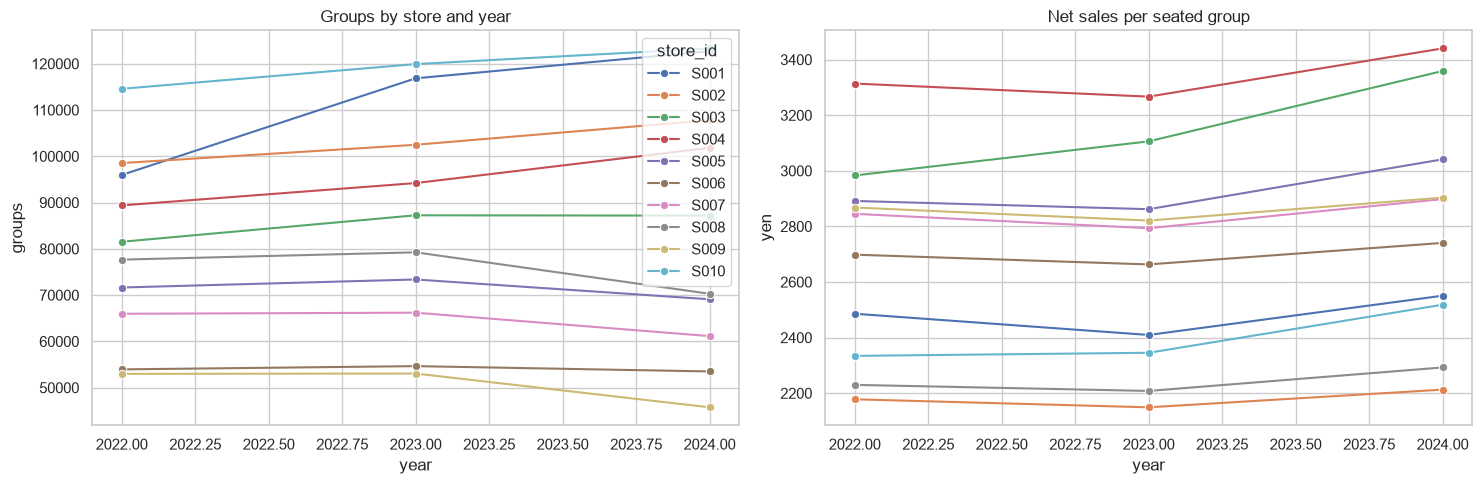

In [4]:
annual=visits_year.groupby('year')[['groups','guests','seated','left','net','wait_sum','wait_count']].sum()
annual['left_rate']=annual.left/annual.groups; annual['yen_per_seated_group']=annual.net/annual.seated; annual['yen_per_all_visitors']=annual.net/annual.guests; annual['mean_wait']=annual.wait_sum/annual.wait_count
display(annual)
by_store=visits_year.copy();by_store['left_rate']=by_store.left/by_store.groups; by_store['yen_per_seated_group']=by_store.net/by_store.seated
display(by_store.pivot(index='store_id',columns='year',values='left_rate'))
fig,ax=plt.subplots(1,2,figsize=(15,5));sns.lineplot(data=by_store,x='year',y='groups',hue='store_id',marker='o',ax=ax[0]);ax[0].set(title='Groups by store and year');sns.lineplot(data=by_store,x='year',y='yen_per_seated_group',hue='store_id',marker='o',legend=False,ax=ax[1]);ax[1].set(title='Net sales per seated group',ylabel='yen');plt.tight_layout();plt.show()

## 待ち時間と離脱・客層
待ち時間は来店時点から着席または離脱までの結果であり、離脱が先に発生すると待ち時間も短くなる。以下は観測上の関係で、待つ時間を操作した場合の因果効果ではない。

,groups,left,left_rate
wait_bin,,,
0,1789775,0,0.000
1-5,253113,24906,0.098
6-10,233794,46545,0.199
11-15,133112,39720,0.298
16-30,81995,43150,0.526
31+,91,77,0.846


,groups,left,net,left_rate,net_per_arriving_group
group_size,,,,,
1,701984,14990,"816,325,739.000",0.021,"1,162.884"
2,969181,26559,"2,229,813,154.000",0.027,"2,300.719"
3,410799,47990,"1,399,688,732.000",0.117,"3,407.235"
4,324456,39262,"1,432,146,496.000",0.121,"4,413.993"
5,85460,25597,"377,621,728.000",0.300,"4,418.696"


groups   left  guests             net  left_rate
year segment                                                  
2022 couple   141471   3841  282942 327,570,629.000      0.027
     family   208654  31985  774455 810,230,421.000      0.153
     senior   115013   1715  166486 197,602,855.000      0.015
     single    50642   1981   50642  55,714,846.000      0.039
     student   95256   4673  219878 260,586,436.000      0.049
     worker   191115  13956  323221 315,120,451.000      0.073
2023 couple   158670   3563  317340 370,277,846.000      0.022
     family   210813  32520  787398 823,648,088.000      0.154
     senior   117805   1466  170889 203,705,599.000      0.012
     single    61520   1227   61520  69,079,322.000      0.020
     student  102579   4554  235666 281,832,443.000      0.044
     worker   195802  12026  330818 326,245,602.000      0.061
2024 couple   169013   2652  338026 421,380,197.000      0.016
     family   201574  24866  755847 863,010,594.000      0.123
     senior   116239    959  168063 212,835,685.000      0.008
     single    68823    561   68823  82,902,940.000      0.008
     student  101238   3370  232509 298,953,326.000      0.033
     worker   185653   8483  313344 334,898,569.000      0.046

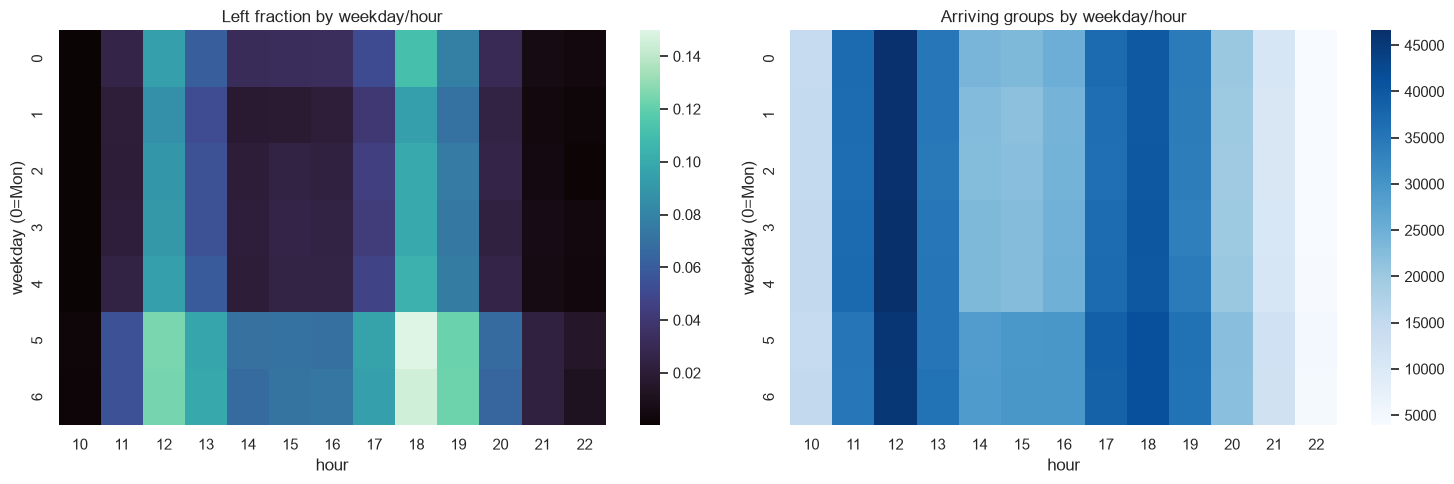

In [5]:
wait=pd.concat(visits_wait).groupby('wait_bin',observed=True)[['groups','left']].sum();wait['left_rate']=wait.left/wait.groups;display(wait)
size=pd.concat(visits_size).groupby('group_size')[['groups','left','net']].sum();size['left_rate']=size.left/size.groups;size['net_per_arriving_group']=size.net/size.groups;display(size)
seg=pd.concat(visits_segment).groupby(['year','segment'],observed=True)[['groups','left','guests','net']].sum();seg['left_rate']=seg.left/seg.groups;display(seg)
hours=pd.concat(visits_hour).groupby(['weekday','hour'],observed=True)[['groups','left']].sum();hours['left_rate']=hours.left/hours.groups
fig,ax=plt.subplots(1,2,figsize=(15,5));sns.heatmap(hours.left_rate.unstack('hour').astype(float),cmap='mako',ax=ax[0]);ax[0].set(title='Left fraction by weekday/hour',ylabel='weekday (0=Mon)');sns.heatmap(hours.groups.unstack('hour').astype(float),cmap='Blues',ax=ax[1]);ax[1].set(title='Arriving groups by weekday/hour',ylabel='weekday (0=Mon)');plt.tight_layout();plt.show()

## 数量・値引き・売上の年次変化
平均実現単価は売上を数量で割ったもの。商品構成の違いを含み、価格改定の効果を単独では表さない。

In [6]:
oy=order_year.groupby('year')[['lines','quantity','list_sales','discount','net','coupon_lines']].sum();oy['net_per_unit']=oy.net/oy.quantity;oy['discount_fraction']=oy.discount/oy.list_sales;oy['coupon_line_fraction']=oy.coupon_lines/oy.lines;display(oy)
menus=pd.read_csv(INPUT/'menus.csv'); iy=pd.concat(item_year).merge(menus[['item_id','category','menu_type']],on='item_id',validate='many_to_one')
cat=iy.groupby(['year','category'],observed=True)[['quantity','net','discount']].sum();cat['net_per_unit']=cat.net/cat.quantity;display(cat)
print('値引き適用は明細実績であり、キャンペーン予定の有無とは異なる。')

値引き適用は明細実績であり、キャンペーン予定の有無とは異なる。


,lines,quantity,list_sales,discount,net,coupon_lines,net_per_unit,discount_fraction,coupon_line_fraction
year,,,,,,,,,
2022,2697160,3229036,1969922740,3097102,1966825638,57118,609.106,0.002,0.021
2023,2843065,3391702,2078330040,3541140,2074788900,63437,611.725,0.002,0.022
2024,2877365,3424650,2217963260,3981949,2213981311,66064,646.484,0.002,0.023


quantity         net  discount  net_per_unit
year category                                               
2022 dessert      198276    99098909   1013611       499.803
     drink_bar   1057740   266314020         0       251.776
     kids         112988    71592270    147550       633.627
     lunch        259958   200192671    424819       770.096
     main        1239832  1178109148   1511122       950.217
     side         360242   151518620         0       420.602
2023 dessert      214673   107600322   1091228       501.229
     drink_bar   1104303   278028750         0       251.769
     kids         114008    72041423    167167       631.898
     lunch        266341   205154288    391382       770.269
     main        1317198  1253226547   1891363       951.434
     side         375179   158737570         0       423.098
2024 dessert      227492   117565752   1178408       516.791
     drink_bar   1106418   285633620         0       258.161
     kids         111507    71698872    184268       642.999
     lunch        258549   216406475    329305       837.004
     main        1340776  1357818602   2289968     1,012.711
     side         379908   164857990         0       433.942

## 次の検討
- 店舗ごとの需要水準や平日・週末パターンは、検証基準日より前の期間だけで作る。
- 着席せず帰った組は潜在需要の手掛かりだが、観測された売上そのものではない。席数や待ちとの相関を因果関係と混同しない。
- 先の需要や時間帯の値を使うラグ・移動平均は、1年先を一括予測する条件に合うよう設計する。